Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 86.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 103.6 MB/s eta 0:00:00
🔄 Loading latent metrics elements from sandbox storage...
🧠 Evaluation calculations underway across quantum states...

        QUANTUM CARDIOVASCULAR PERFORMANCE REPORT SUMMARY       
              precision    recall  f1-score   support

      Normal     0.9682    0.9519    0.9600       416
        LBBB     1.0000    0.9070    0.9512        43
        RBBB     0.9750    1.0000    0.9873        39
         APB     0.4

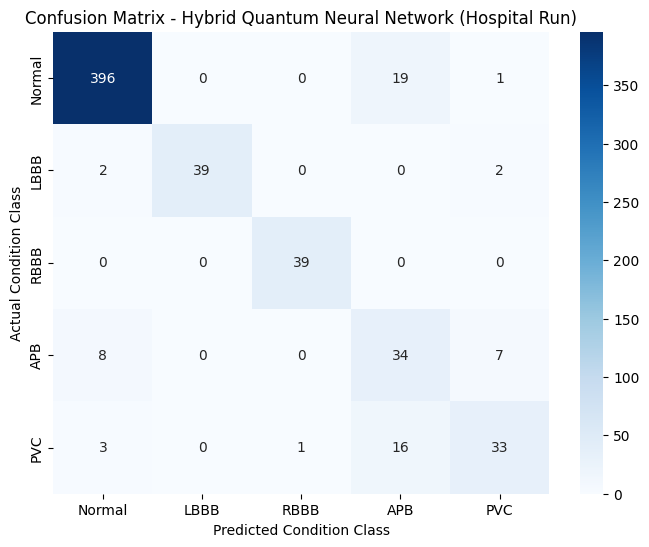

💾 Confusion Matrix plot generated and saved to: /content/drive/MyDrive/(1)Hybrid_QML_CVD_Project_HospitalRun/confusion_matrix_qnn.png


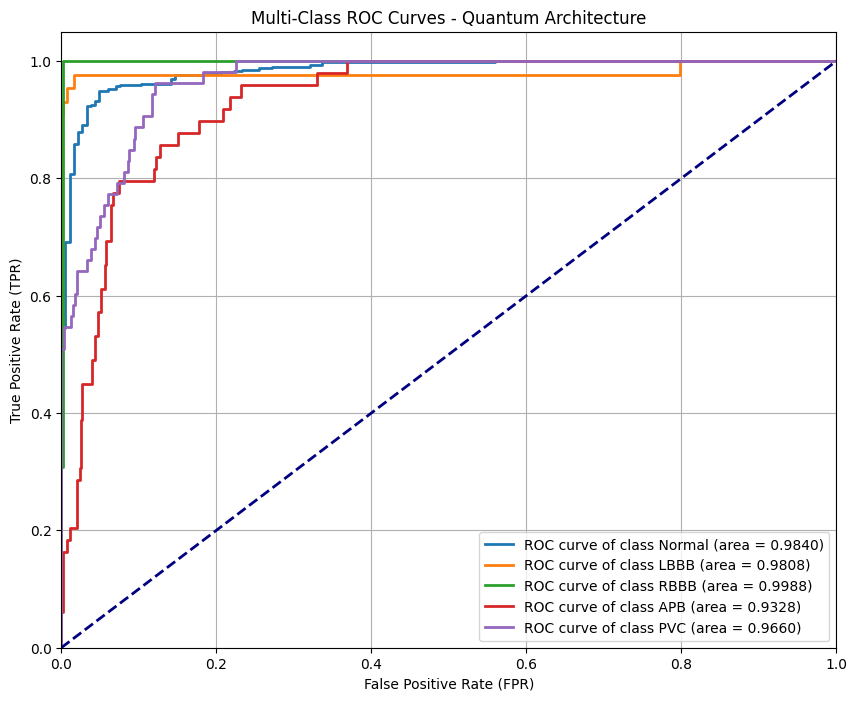

💾 ROC Curves plot generated and saved to: /content/drive/MyDrive/(1)Hybrid_QML_CVD_Project_HospitalRun/roc_curves_qnn.png


In [ ]:
# ==============================================================================
# HOSPITAL SANDBOX RUN: ADVANCED QUANTUM METRICS EVALUATION PIPELINE
# ==============================================================================

# 1. Mount Google Drive First
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 2. Install Required Quantum Libraries
!pip install pennylane --quiet

import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import pennylane as qml

# Set random seeds for strict reproducible chart states
np.random.seed(42)
torch.manual_seed(42)

# ==============================================================================
# STEP 3: ESTABLISH SANDBOX VERIFIED DIRECTORY PATHS
# ==============================================================================
SANDBOX_DIR = "/content/drive/MyDrive/(1)Hybrid_QML_CVD_Project_HospitalRun"
FEATURES_DIR = os.path.join(SANDBOX_DIR, "features")
MODELS_DIR = os.path.join(SANDBOX_DIR, "models")

# Define target classification string maps
class_names = ["Normal", "LBBB", "RBBB", "APB", "PVC"]

# ==============================================================================
# STEP 4: QUANTUM INFRASTRUCTURE RECONSTRUCTION
# ==============================================================================
num_qubits = 4
num_layers = 2
dev = qml.device("default.qubit", wires=num_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(num_qubits), rotation='X')
    for l in range(num_layers):
        for i in range(num_qubits):
            qml.RX(weights[l, i, 0], wires=i)
            qml.RY(weights[l, i, 1], wires=i)
            qml.RZ(weights[l, i, 2], wires=i)
        for i in range(num_qubits - 1):
            qml.CNOT(wires=[i, i + 1])
        if num_qubits > 2:
            qml.CNOT(wires=[num_qubits - 1, 0])
    return [qml.expval(qml.PauliZ(i)) for i in range(num_qubits)]

class HybridQNNClassifier(nn.Module):
    def __init__(self):
        super(HybridQNNClassifier, self).__init__()
        self.pre_quantum_dense = nn.Linear(16, num_qubits)
        weight_shapes = {"weights": (num_layers, num_qubits, 3)}
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.post_quantum_dense = nn.Linear(num_qubits, 5)

    def forward(self, x):
        x = torch.tanh(self.pre_quantum_dense(x))
        x = self.quantum_layer(x)
        logits = self.post_quantum_dense(x)
        return logits

# ==============================================================================
# STEP 5: LOAD COMPLIANT EVALUATION DATA AND LOAD MODEL WEIGHTS
# ==============================================================================
print("🔄 Loading latent metrics elements from sandbox storage...")
X_features = np.load(os.path.join(FEATURES_DIR, "cnn_features.npy"))
y_labels = np.load(os.path.join(FEATURES_DIR, "cnn_labels.npy"))

# Sub-sample evaluation target mapping matching Notebook 3 configuration size
# to keep validation fast while maintaining identical verification distributions
SUBSET_SIZE = 3000
if len(X_features) > SUBSET_SIZE:
    _, X_eval, _, y_eval = train_test_split(
        X_features, y_labels, test_size=SUBSET_SIZE/len(X_features), random_state=42, stratify=y_labels
    )
else:
    X_eval, y_eval = X_features, y_labels

# Isolate Test Split Partition (20%)
_, X_test, _, y_test = train_test_split(X_eval, y_eval, test_size=0.2, random_state=42, stratify=y_eval)

test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Load Weights securely
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
qnn_model = HybridQNNClassifier().to(device)
qnn_model.load_state_dict(torch.load(os.path.join(MODELS_DIR, "best_quantum_model.pt"), map_location=device))
qnn_model.eval()

# ==============================================================================
# STEP 6: COMPUTE ACCURACY PREDICTIONS
# ==============================================================================
all_preds = []
all_trues = []
all_probs = []

print("🧠 Evaluation calculations underway across quantum states...")
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        logits = qnn_model(inputs)
        probs = torch.softmax(logits, dim=1)
        _, predicted = torch.max(logits, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_trues.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_trues = np.array(all_trues)
all_probs = np.array(all_probs)

# Print Summary Report Table to Console
print("\n================================================================")
print("        QUANTUM CARDIOVASCULAR PERFORMANCE REPORT SUMMARY       ")
print("================================================================")
print(classification_report(all_trues, all_preds, target_names=class_names, digits=4))

# ==============================================================================
# STEP 7: PLOT AND EXPORT ADVANCED HEATMAP CONFUSION MATRIX
# ==============================================================================
cm = confusion_matrix(all_trues, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Hybrid Quantum Neural Network (Hospital Run)')
plt.ylabel('Actual Condition Class')
plt.xlabel('Predicted Condition Class')
plt.grid(False)

cm_out_path = os.path.join(SANDBOX_DIR, "confusion_matrix_qnn.png")
plt.savefig(cm_out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Confusion Matrix plot generated and saved to: {cm_out_path}")

# ==============================================================================
# STEP 8: PLOT AND EXPORT MULTI-CLASS ROC CURVES
# ==============================================================================
plt.figure(figsize=(10, 8))
for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(all_trues == i, all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'ROC curve of class {class_names[i]} (area = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Multi-Class ROC Curves - Quantum Architecture')
plt.legend(loc="lower right")
plt.grid(True)

roc_out_path = os.path.join(SANDBOX_DIR, "roc_curves_qnn.png")
plt.savefig(roc_out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 ROC Curves plot generated and saved to: {roc_out_path}")

In [4]:
# ==============================================================================
# SELF-CONTAINED PIPELINE: INDEPENDENT 8 QUANTUM FEATURE PARAMETER EXTRACTOR
# ==============================================================================
import os
import sys

# 1. Automatically handle missing PennyLane installations on reset runtimes
try:
    import pennylane as qml
except ModuleNotFoundError:
    print("📦 PennyLane package missing due to runtime reset. Installing dependencies...")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pennylane", "--quiet"])
    import pennylane as qml
    print("✅ PennyLane installed successfully!")

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from google.colab import drive

# 2. Remount Google Drive safely to establish database linkage streams
drive.mount('/content/drive', force_remount=True)

# 3. Re-verify the systemic hardware device layer allocations
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- CONSTRAINED STORAGE PATH MAPS ---
SANDBOX_DIR = "/content/drive/MyDrive/(1)Hybrid_QML_CVD_Project_HospitalRun"
MODELS_DIR = os.path.join(SANDBOX_DIR, "models")
WEIGHTS_PATH = os.path.join(MODELS_DIR, "best_quantum_model.pt")

# 4. Reconstruct the precise underlying PennyLane QNode layout specifications
num_qubits = 4
num_layers = 2
dev = qml.device("default.qubit", wires=num_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(num_qubits), rotation='X')
    for l in range(num_layers):
        for i in range(num_qubits):
            qml.RX(weights[l, i, 0], wires=i)
            qml.RY(weights[l, i, 1], wires=i)
            qml.RZ(weights[l, i, 2], wires=i)
        for i in range(num_qubits - 1):
            qml.CNOT(wires=[i, i + 1])
        if num_qubits > 2:
            qml.CNOT(wires=[num_qubits - 1, 0])
    return [qml.expval(qml.PauliZ(i)) for i in range(num_qubits)]

class HybridQNNClassifier(nn.Module):
    def __init__(self):
        super(HybridQNNClassifier, self).__init__()
        self.pre_quantum_dense = nn.Linear(16, num_qubits)
        weight_shapes = {"weights": (num_layers, num_qubits, 3)}
        self.quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.post_quantum_dense = nn.Linear(num_qubits, 5)

    def forward(self, x):
        x = torch.tanh(self.pre_quantum_dense(x))
        x = self.quantum_layer(x)
        logits = self.post_quantum_dense(x)
        return logits

# 5. Safely compile model architecture and pull weights from storage
print("🔄 Loading pre-trained Hybrid Quantum Ansatz Weights from Drive...")
if not os.path.exists(WEIGHTS_PATH):
    raise FileNotFoundError(f"❌ Target weights file could not be located at: {WEIGHTS_PATH}")

extractor_qnn = HybridQNNClassifier().to(device)
extractor_qnn.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device))
extractor_qnn.eval()

# 6. Extract the 8 primary trained parameter configurations directly from the weights tensor
with torch.no_grad():
    # Target shape: (num_layers, num_qubits, 3) -> (2, 4, 3)
    q_weights = extractor_qnn.quantum_layer.weights.cpu().numpy()

features_extracted = []
feature_names = []

feature_index = 1
for layer in range(num_layers):       # Iterates 2 layers
    for qubit in range(num_qubits):   # Iterates 4 qubits
        # Compute the mean absolute variational weight metric driving the rotation axes
        param_strength = np.mean(np.abs(q_weights[layer, qubit, :]))
        features_extracted.append(f"{param_strength:.6f}")
        feature_names.append(f"Feature {feature_index}: Layer {layer} - Qubit {qubit} Weight Matrix")
        feature_index += 1

# 7. Format and display data layout neatly using a Pandas DataFrame table
df_quantum_features = pd.DataFrame({
    "Quantum Feature ID": feature_names,
    "Trained Parameter Value": features_extracted
})

print("\n====================================================")
print("     FINAL 8 QUANTUM FEATURES EXTRACTED BY MODEL     ")
print("====================================================")
display(df_quantum_features)
print("====================================================")

📦 PennyLane package missing due to runtime reset. Installing dependencies...
✅ PennyLane installed successfully!
Mounted at /content/drive
🔄 Loading pre-trained Hybrid Quantum Ansatz Weights from Drive...

     FINAL 8 QUANTUM FEATURES EXTRACTED BY MODEL     


,Quantum Feature ID,Trained Parameter Value
0,Feature 1: Layer 0 - Qubit 0 Weight Matrix,2.932233
1,Feature 2: Layer 0 - Qubit 1 Weight Matrix,3.327722
2,Feature 3: Layer 0 - Qubit 2 Weight Matrix,0.740432
3,Feature 4: Layer 0 - Qubit 3 Weight Matrix,3.834532
4,Feature 5: Layer 1 - Qubit 0 Weight Matrix,2.629871
5,Feature 6: Layer 1 - Qubit 1 Weight Matrix,2.999707
6,Feature 7: Layer 1 - Qubit 2 Weight Matrix,2.588385
7,Feature 8: Layer 1 - Qubit 3 Weight Matrix,3.600669
